# Transformers Latent Stable Difussion. Flowers class-to-image

In [5]:
from FlowerDataset import FlowersDataset
from scipy.io import loadmat
import json
import matplotlib.pyplot as plt
import numpy as np
import torch
import diffusers
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import time
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:

n_classes = 102

## Dataset load

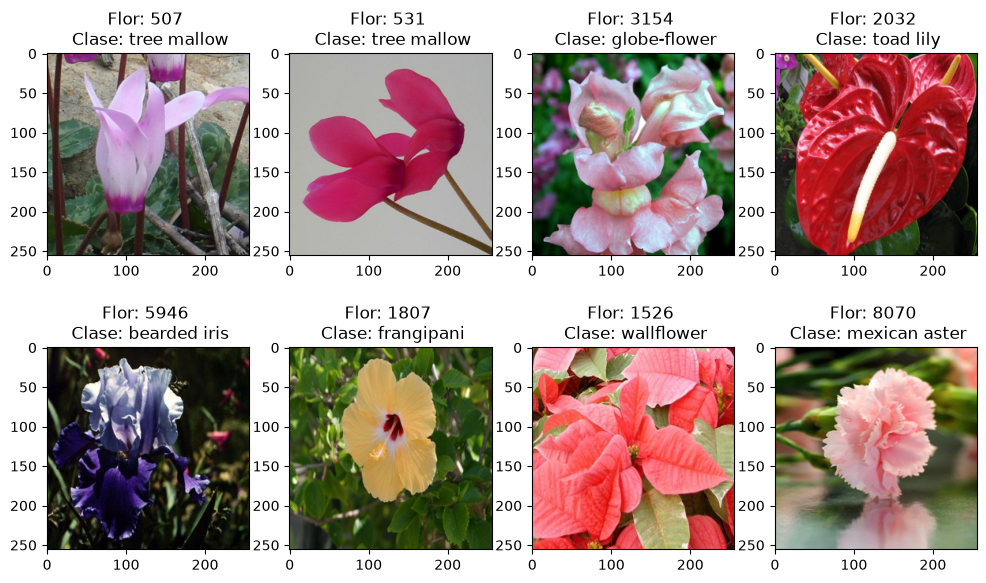

In [3]:

labels = loadmat("./flower_labels.mat")["labels"][0]

label_mapping = json.load(open("label_mapping.json", "r", encoding="utf-8"))
label_mapping = {v: k for k, v in label_mapping.items()}

dataset = FlowersDataset(labels, image_size=256)

fig, axs = plt.subplots(2, 4, figsize=(12,7))

for ax in axs.flat:
    id = np.random.randint(0, len(labels))
    img, label = dataset[id]
    

    ax.imshow((img.permute(1, 2, 0)/2 + 0.5).numpy())
    ax.set_title(f"Flor: {id} \n Clase: {label_mapping[int(label)]}")
    
plt.show()


# VAE 
The VAE is needed to, compact the image information into a latent space to allow the diffusion model to reconstruct this latent and the VAE decoder to finally generate the image.

In [6]:

vae = diffusers.AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device)

In [7]:
vae.eval()
vae.requires_grad_(False)

AutoencoderKL(
  (encoder): Encoder(
    (conv_in): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (down_blocks): ModuleList(
      (0): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0-1): 2 x ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm2): GroupNorm(32, 128, eps=1e-06, affine=True)
            (dropout): Dropout(p=0.0, inplace=False)
            (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (nonlinearity): SiLU()
          )
        )
        (downsamplers): ModuleList(
          (0): Downsample2D(
            (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2))
          )
        )
      )
      (1): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0): ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (c

# Image reconstruction test

torch.Size([1, 4, 32, 32])
torch.Size([1, 3, 256, 256])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.2448013..1.0934725].


torch.Size([3, 256, 256])
torch.Size([3, 256, 256])


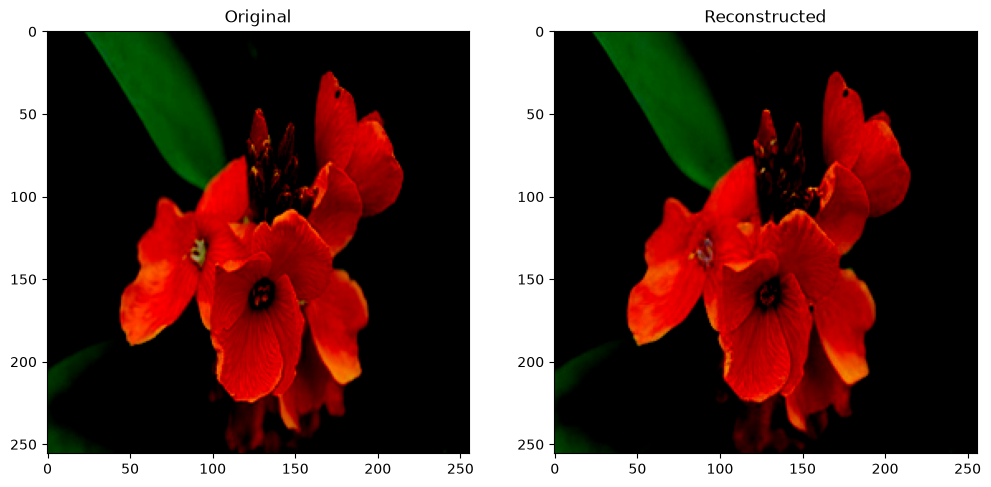

In [6]:
test_id = 980

image_test, label_test = dataset[test_id]

image_test = image_test.unsqueeze(0).to(device)

out = vae.encode(image_test)

print(out.latent_dist.sample().shape)

reconstructed_image = vae.decode(out.latent_dist.sample()).sample

print(reconstructed_image.shape)

fig, axs = plt.subplots(1,2, figsize=(12, 7))

image_test = image_test.squeeze(0).to("cpu")
reconstructed_image = reconstructed_image.squeeze(0).to("cpu")

print(image_test.shape)
print(reconstructed_image.shape)

axs[0].imshow(image_test.permute(1, 2, 0))
axs[1].imshow(reconstructed_image.permute(1, 2, 0))

axs[0].set_title("Original")
axs[1].set_title("Reconstructed")

plt.show()

# Transformers latent stable difussion model

In [2]:
import torch.nn as nn
import math

class Patchify(nn.Module):
    def __init__(self, patch_size = 2, warm_up_layers = 0, embedding_dim = 256, in_channels = 3):
        super().__init__()

        assert patch_size > 0 and patch_size.bit_count() == 1
        assert warm_up_layers >= 0
        assert embedding_dim > 0 and embedding_dim.bit_count() == 1
        
        power = int(math.log2(embedding_dim))
        
        assert power > warm_up_layers + 1
        
        self.conv_blocks = []
        in_c = in_channels
        out_c = None
        for i in range(warm_up_layers):
            out_c = 2 ** (power - (warm_up_layers - i))
            self.conv_blocks.append(
                
                nn.Conv2d(in_channels=in_c, 
                          out_channels=out_c,
                          kernel_size=patch_size,
                          stride=1,
                          padding='same',
                          )
            )
            in_c = out_c
            
            self.conv_blocks.append(nn.ReLU())
        
        self.conv_blocks.append(
            nn.Conv2d(in_channels=in_c,
                      out_channels=embedding_dim,
                      kernel_size=patch_size,
                      stride= patch_size,
                      padding= 0,
                      )
        )

        self.conv_blocks = nn.Sequential(*self.conv_blocks)
        
        self.res_trans = nn.Sequential(
            nn.AvgPool2d(
                kernel_size=patch_size,
                stride=patch_size
            ),
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=embedding_dim,
                kernel_size=1
            )
        )
        
        
    def forward(self, x):
        
        res = self.res_trans(x)
        y = self.conv_blocks(x)
        
        return y + res
        

class TransformerBlock(nn.Module):
    def __init__(self, embedding_dim, num_heads):
        super().__init__()
        
        self.adaLN = nn.Sequential(
            nn.SiLU(),
            nn.Linear(embedding_dim, embedding_dim * 6)
            )
        
        nn.init.zeros_(self.adaLN[-1].weight)
        nn.init.zeros_(self.adaLN[-1].bias)
        
        self.attnblck = nn.MultiheadAttention(embedding_dim,num_heads, batch_first=True)
        
        self.ff_layer = nn.Sequential(
            nn.Linear(embedding_dim, embedding_dim * 4),
            nn.GELU(),
            nn.Linear(embedding_dim * 4, embedding_dim)
        )
        
        self.in_norm = nn.LayerNorm(embedding_dim, elementwise_affine=False)
        self.post_attention_norm = nn.LayerNorm(embedding_dim, elementwise_affine=False)
        
    def forward(self, x, condition_tensor):
        
        shift1, scale1, gate1, shift2, scale2, gate2 = (
            self.adaLN(condition_tensor).chunk(6, dim=-1)
        )
        
        y = self.in_norm(x)
        y = y * (1 + scale1.unsqueeze(1)) + shift1.unsqueeze(1)
        
        y = self.attnblck(y, y, y, need_weights=False)[0]
        x = x + gate1.unsqueeze(1) * y
        
        y = self.post_attention_norm(x)
        y = y * (1 + scale2.unsqueeze(1)) + shift2.unsqueeze(1)
        
        y = self.ff_layer(y)
        
        ret = x + gate2.unsqueeze(1) * y
        
        return ret
        
        

class ClassEmbeddings(nn.Module):
    def __init__(self, dim, n_classes):
        super().__init__()
        self.embeddings = nn.Embedding(n_classes, dim)
    
    def forward(self, label):
        ret = self.embeddings(label)
        
        return ret
    
class TimeStepEmbeddings(nn.Module):
    def __init__(self, dim, max_period=10000):
        super().__init__()
        self.dim = dim
        self.max_period = max_period

        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.SiLU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, t):
        half = self.dim // 2

        freqs = torch.exp(
            -math.log(self.max_period)
            * torch.arange(half, device=t.device, dtype=torch.float32)
            / half
        )

        args = t.float().unsqueeze(1) * freqs.unsqueeze(0)

        embedding = torch.cat(
            [torch.cos(args), torch.sin(args)], dim=-1
        )

        if self.dim % 2:
            embedding = torch.nn.functional.pad(embedding, (0, 1))

        return self.mlp(embedding)
    

class DiT(nn.Module):
    def __init__(self, n_classes, embedding_dim, patch_size, patch_warm_up_layers, condition_embedding_size, n_transformer_blocks, transformer_heads , in_channels, in_res, max_steps):
        super().__init__()
        
        self.class_embeddings = ClassEmbeddings(condition_embedding_size, n_classes)
        self.timestep_embeddings = TimeStepEmbeddings(condition_embedding_size, max_steps)
        
        self.patchify = Patchify(patch_size,patch_warm_up_layers,embedding_dim, in_channels)
        
        self.unpatchify = nn.Linear(embedding_dim, (in_channels * patch_size * patch_size))
        
        self.transformer_blocks = nn.ModuleList()
        
        for _ in range(n_transformer_blocks):
            self.transformer_blocks.append(TransformerBlock(embedding_dim, num_heads=transformer_heads))
        
        self.pos_emb = nn.Parameter(torch.randn(1, (in_res // patch_size) ** 2, embedding_dim) * 0.02)
        self.in_res = in_res
        self.in_channels = in_channels
        self.patch_size = patch_size
    
    def forward(self, x, t, labels):
        
        c_emb = self.class_embeddings(labels)
        t_emb = self.timestep_embeddings(t)
        
        condition = c_emb + t_emb
        
        y = self.patchify(x)

        y = y.flatten(2).transpose(1, 2)

        y = y + self.pos_emb
        
        for block in self.transformer_blocks:
            y = block(y, condition)
            
        y = self.unpatchify(y)
        
        B, _, _ = y.shape
        
        
        rec_size = self.in_res // self.patch_size
        y = y.reshape(B, rec_size, rec_size, self.patch_size, self.patch_size, self.in_channels)
        y = y.permute(0, 5, 1, 3, 2, 4)
        y = y.reshape(B, self.in_channels, self.in_res, self.in_res)
        
        return y



# Modules tests

In [8]:
image_test, label_test = dataset[0]

image_test = image_test.unsqueeze(0).to(device)

p_test = Patchify(8, 2, 256, 3).to(device)

out = p_test(image_test)

print(out.shape)

out = out.flatten(2)

print(out.shape)

out = out.transpose(2, 1)

print(out.shape)

class_embeddings = ClassEmbeddings(256, 102).to(device)
t_block_test = TransformerBlock(256, 8).to(device)

test_condition = class_embeddings(torch.Tensor(1).long().to(device))
print(test_condition.shape)
out = t_block_test(out, test_condition)

print(out.shape)


torch.Size([1, 256, 32, 32])
torch.Size([1, 256, 1024])
torch.Size([1, 1024, 256])
torch.Size([1, 256])
torch.Size([1, 1024, 256])


c:\Users\javie\Desktop\FlowerLatentStableDifussion\venv\Lib\site-packages\torch\nn\modules\conv.py:548: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Convolution.cpp:1025.)
  return F.conv2d(


In [9]:
image_test, label_test = dataset[0]
image_test = image_test.unsqueeze(0).to(device)
label_test = label_test.unsqueeze(0).to(device)

latent_test = vae.encode(image_test)
latent_test = latent_test.latent_dist.sample()

print(latent_test.shape)

model = DiT(n_classes=102,embedding_dim=256, patch_size=4, patch_warm_up_layers=2, condition_embedding_size=256,n_transformer_blocks=3, transformer_heads=4, in_channels=4, in_res = 32, max_steps = 1000).to(device)

timestep_test = torch.Tensor(1).long().to(device)
print(timestep_test.shape)

out = model(latent_test, timestep_test, label_test)

print(out.shape)


torch.Size([1, 4, 32, 32])
torch.Size([1])
torch.Size([1, 4, 32, 32])


# Data pre processing


In [10]:
labels = loadmat("./flower_labels.mat")["labels"][0]
dataset = FlowersDataset(labels, image_size=256)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

all_latents = []
all_labels = []

vae = vae.to(device)
vae.eval()

dataloader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=False,
    pin_memory=True,
    num_workers=4
)

with torch.no_grad():
    for i, (images, labels) in enumerate(dataloader):
        images = images.to(device, non_blocking=True)
        dist = vae.encode(images).latent_dist

        for _ in range(10):
            latents = dist.sample() * vae.config.scaling_factor
            all_latents.append(latents.cpu().half())
            all_labels.append(labels.clone())

        print(f"Batch {i + 1}/{len(dataloader)} procesado")


latents = torch.cat(all_latents, dim=0)
labels = torch.cat(all_labels, dim=0)

torch.save({
    "latents": latents,
    "labels": labels
}, "flower_latents.pt")


Batch 1/128 procesado
Batch 2/128 procesado
Batch 3/128 procesado
Batch 4/128 procesado
Batch 5/128 procesado
Batch 6/128 procesado
Batch 7/128 procesado
Batch 8/128 procesado
Batch 9/128 procesado
Batch 10/128 procesado
Batch 11/128 procesado
Batch 12/128 procesado
Batch 13/128 procesado
Batch 14/128 procesado
Batch 15/128 procesado
Batch 16/128 procesado
Batch 17/128 procesado
Batch 18/128 procesado
Batch 19/128 procesado
Batch 20/128 procesado
Batch 21/128 procesado
Batch 22/128 procesado
Batch 23/128 procesado
Batch 24/128 procesado
Batch 25/128 procesado
Batch 26/128 procesado
Batch 27/128 procesado
Batch 28/128 procesado
Batch 29/128 procesado
Batch 30/128 procesado
Batch 31/128 procesado
Batch 32/128 procesado
Batch 33/128 procesado
Batch 34/128 procesado
Batch 35/128 procesado
Batch 36/128 procesado
Batch 37/128 procesado
Batch 38/128 procesado
Batch 39/128 procesado
Batch 40/128 procesado
Batch 41/128 procesado
Batch 42/128 procesado
Batch 43/128 procesado
Batch 44/128 procesa

# Model Training

In [6]:
epochs = 100
lr = 1e-3
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

n_classes = 102
embedding_dim = 256
patch_size = 4
patch_warm_up = 2
condition_embedding = 256
n_transformer_blocks = 3
transformer_heads = 4
in_channels, in_res , _ = (4,32,32)
max_steps = 1000

vae = vae.requires_grad_(False).to(device)
vae.eval()

dit = DiT(n_classes, embedding_dim, patch_size, patch_warm_up, condition_embedding, n_transformer_blocks, transformer_heads, in_channels, in_res, max_steps).to(device)

total = sum(p.numel() for p in dit.parameters())
print(f"Numero de parametros totales del modelo: {total}")


data = torch.load("flower_latents.pt", map_location="cpu")

latents = data["latents"].to('cpu').float()
labels = data["labels"].to('cpu')

dataset = TensorDataset(latents, labels)

train_idx, val_idx = train_test_split(
    range(len(dataset)),
    test_size=0.2,
    stratify=labels,
    random_state=42
)

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)

BATCH_SIZE = 64

train_dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=True,
    num_workers=4
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=True,
    num_workers=4
)

optimizer = torch.optim.AdamW(dit.parameters(), lr=lr)
loss_fn = torch.nn.MSELoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

def train_step(dit, images, labels):

    images = images.to(device, non_blocking = True)
    labels = labels.to(device, non_blocking = True)
        
    noise = torch.randn_like(images).to(device, non_blocking=True)
    timesteps = torch.rand(images.shape[0]).to(device, non_blocking=True)
    t_expanded = timesteps.view(-1, 1, 1, 1)
    
    x_t = (1 - t_expanded) * noise + t_expanded * images
    
    target = images - noise
    
    optimizer.zero_grad()
    
    out = dit(x_t, timesteps * 1000, labels)
    
    loss = loss_fn(out.float(), target.float())
    
    loss.backward()
    optimizer.step()
    
    return loss.item()
    
    
    

def val_step(dit, images, labels):
    images = images.to(device, non_blocking = True)
    labels = labels.to(device, non_blocking = True)
        
    noise = torch.randn_like(images).to(device, non_blocking=True)
    timesteps = torch.rand(images.shape[0]).to(device, non_blocking=True)
    t_expanded = timesteps.view(-1, 1, 1, 1)
    
    x_t = (1 - t_expanded) * noise + t_expanded * images
    
    target = images - noise
    
    
    out = dit(x_t, timesteps * 1000, labels)
    
    loss = loss_fn(out.float(), target.float())
    
    return loss.item()

Numero de parametros totales del modelo: 4796160


In [7]:
patience = 5
min_val_loss = float("inf")
epochs_wo_imp = 0

for e in range(epochs):
    start = time.time()

    dit.train()
    train_loss = 0.0
    for images, labels in train_dataloader:
        train_loss += train_step(dit, images, labels)

    train_loss /= len(train_dataloader)
        
    val_loss = 0.0
    dit.eval()
    with torch.no_grad():
        for images, labels in val_dataloader:
            val_loss += val_step(dit, images, labels)
        
    val_loss /= len(val_dataloader)
    
    scheduler.step(val_loss)
    
    elapsed = time.time() - start
    
    print(
        f"Epoch: {e + 1}/{epochs} | "
        f"Time: {elapsed:.2f}s | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )
    
    if val_loss <= min_val_loss:
        epochs_wo_imp = 0
        min_val_loss = val_loss
        
        torch.save({
            "epoch": e + 1,
            "model_state_dict": dit.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
        }, "best_dit.pt")
    else:
        epochs_wo_imp += 1
        
    if epochs_wo_imp >= patience:
        print("Patience ran out, ending training...")
        break

c:\Users\javie\Desktop\FlowerLatentStableDifussion\venv\Lib\site-packages\torch\nn\modules\conv.py:548: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Convolution.cpp:1025.)
  return F.conv2d(


Epoch: 1/100 | Time: 67.21s | Train Loss: 1.031891 | Val Loss: 0.968460
Epoch: 2/100 | Time: 63.18s | Train Loss: 0.955509 | Val Loss: 0.942643
Epoch: 3/100 | Time: 59.50s | Train Loss: 0.937618 | Val Loss: 0.934450
Epoch: 4/100 | Time: 58.07s | Train Loss: 0.930449 | Val Loss: 0.929346
Epoch: 5/100 | Time: 58.91s | Train Loss: 0.924998 | Val Loss: 0.923114
Epoch: 6/100 | Time: 61.16s | Train Loss: 0.919886 | Val Loss: 0.918548
Epoch: 7/100 | Time: 59.77s | Train Loss: 0.915019 | Val Loss: 0.913143
Epoch: 8/100 | Time: 70.73s | Train Loss: 0.910306 | Val Loss: 0.915147
Epoch: 9/100 | Time: 67.85s | Train Loss: 0.909709 | Val Loss: 0.906729
Epoch: 10/100 | Time: 60.79s | Train Loss: 0.906960 | Val Loss: 0.907034
Epoch: 11/100 | Time: 66.31s | Train Loss: 0.903677 | Val Loss: 0.901663
Epoch: 12/100 | Time: 67.77s | Train Loss: 0.901970 | Val Loss: 0.902279
Epoch: 13/100 | Time: 68.98s | Train Loss: 0.901228 | Val Loss: 0.897762
Epoch: 14/100 | Time: 79.17s | Train Loss: 0.899053 | Val Lo

# Model evaluation

In [8]:
n_classes = 102
embedding_dim = 256
patch_size = 4
patch_warm_up = 2
condition_embedding = 256
n_transformer_blocks = 3
transformer_heads = 4
in_channels, in_res , _ = (4,32,32)
max_steps = 1000

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

dit = DiT(n_classes, embedding_dim, patch_size, patch_warm_up, condition_embedding, n_transformer_blocks, transformer_heads, in_channels, in_res, max_steps).to(device)

checkpoint = torch.load(
    "best_dit.pt",
    map_location=device,
    weights_only=True
)

dit.load_state_dict(checkpoint["model_state_dict"])
dit.eval()

vae = vae.to(device).eval()

def generate_image(label, steps):
    dt = 1.0 / steps
    x = torch.randn(1, 4, 32, 32, device = device)
    
    with torch.no_grad():
        for i in range(steps):
            t = torch.full((1,), i * dt, device=device)
            velocity = dit(x, t * 1000, torch.tensor([label], device=device))
            x = x + velocity * dt
        
        x = x / vae.config.scaling_factor
        image = vae.decode(x).sample
        image = (image / 2 + 0.5).clamp(0, 1)

    image = image[0].permute(1, 2, 0).cpu()
    
    
    
    return image

c:\Users\javie\Desktop\FlowerLatentStableDifussion\venv\Lib\site-packages\torch\nn\modules\conv.py:548: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Convolution.cpp:1025.)
  return F.conv2d(


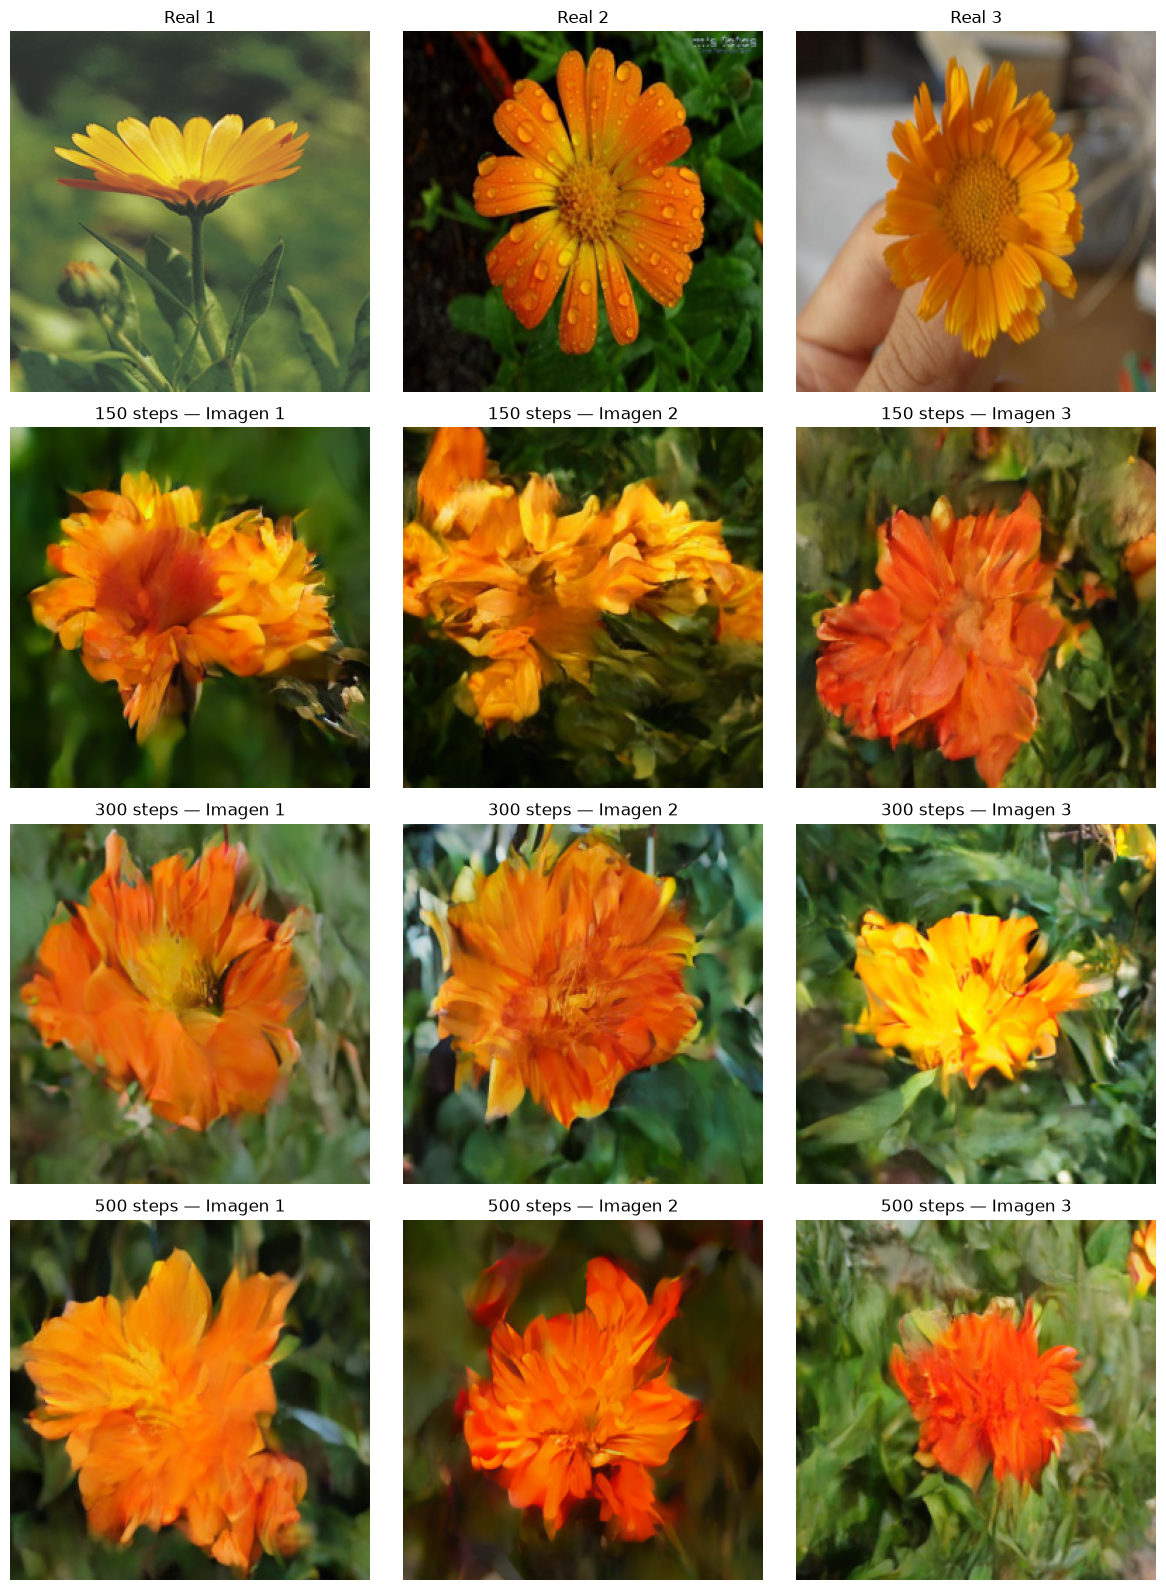

In [ ]:
import random

labels = loadmat("./flower_labels.mat")["labels"][0]

label_mapping = json.load(open("label_mapping.json", "r", encoding="utf-8"))
label_mapping = {v: k for k, v in label_mapping.items()}

dataset = FlowersDataset(labels, image_size=256)

SELECTED_LABEL = 4

indices = [
    i for i, label in enumerate(labels)
    if int(label) == SELECTED_LABEL + 1
]

selected_indices = random.sample(indices, min(3, len(indices)))

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for j, idx in enumerate(selected_indices):
    img, _ = dataset[idx]

    if isinstance(img, torch.Tensor):
        img = img.detach().cpu()
        if img.ndim == 3 and img.shape[0] in (1, 3, 4):
            img = img.permute(1, 2, 0)
        img = img.numpy()

    if img.min() < 0:
        img = (img / 2 + 0.5).clip(0, 1)

    axes[0, j].imshow(img.squeeze())
    axes[0, j].set_title(f"Real {j + 1}")
    axes[0, j].axis("off")

dit.eval()
vae.eval()

steps_list = [150, 300, 500]

for row, steps in enumerate(steps_list, start=1):
    for col in range(3):
        image = generate_image(SELECTED_LABEL, steps)
        
        axes[row, col].imshow(image)
        axes[row, col].set_title(f"{steps} steps — Imagen {col + 1}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

plt.savefig(f"gen{SELECTED_LABEL}.png", dpi=300, bbox_inches="tight")